In [1]:
# Producto A — SVM interactivo: fronteras de decisión + vectores de soporte

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn import svm
from sklearn.datasets import make_moons, make_circles, load_breast_cancer
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_curve, auc
import ipywidgets as widgets
from IPython.display import display, Markdown

plt.rcParams['figure.figsize'] = (8,6)


In [3]:
# Función para plotear SVM
def plot_svm_interactive(kernel='rbf', C=1.0, gamma='scale', degree=3, dataset='moons', noise=0.2, show_sv=True):
    # generar dataset
    if dataset == 'moons':
        X, y = make_moons(n_samples=300, noise=noise, random_state=0)
    else:
        X, y = make_circles(n_samples=300, noise=noise, factor=0.5, random_state=0)

    # escalar
    scaler = StandardScaler()
    X = scaler.fit_transform(X)

    # crear y entrenar SVM
    model = svm.SVC(kernel=kernel, C=C, gamma=gamma, degree=degree)
    model.fit(X, y)

    # preparar grid
    x_min, x_max = X[:,0].min() - .8, X[:,0].max() + .8
    y_min, y_max = X[:,1].min() - .8, X[:,1].max() + .8
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 400), np.linspace(y_min, y_max, 400))
    grid = np.c_[xx.ravel(), yy.ravel()]

    # obtener decisión (distancia a la frontera)
    try:
        Z = model.decision_function(grid)
    except:
        Z = model.predict_proba(grid)[:,1]
    Z = Z.reshape(xx.shape)

    # plot
    cmap_light = ListedColormap(['#FFEEEE','#EEFFEE'])
    cmap_bold = ListedColormap(['#FF0000','#008000'])
    plt.figure(figsize=(8,6))
    plt.contourf(xx, yy, Z > 0, cmap=cmap_light, alpha=0.6)
    plt.contour(xx, yy, Z, levels=[0], linewidths=2, linestyles='--', colors='k')  # frontera (decision boundary)
    plt.scatter(X[:,0], X[:,1], c=y, cmap=cmap_bold, edgecolors='k', s=40)

    if show_sv and hasattr(model, "support_"):
        sv = model.support_vectors_
        plt.scatter(sv[:,0], sv[:,1], s=120, facecolors='none', edgecolors='k', linewidths=1.5, label='support vectors')
        plt.legend()

    plt.title(f"SVM kernel={kernel} | C={C} | gamma={gamma} | degree={degree}\nDataset={dataset}, noise={noise}")
    plt.xlabel("feature 1")
    plt.ylabel("feature 2")
    plt.show()

# widgets
kernel_w = widgets.Dropdown(options=['linear','poly','rbf','sigmoid'], value='rbf', description='kernel:')
C_w = widgets.FloatLogSlider(value=1.0, base=10, min=-2, max=2, step=0.1, description='C:')
# gamma_w = widgets.Dropdown(options=['scale','auto'], value='scale', description='gamma:')
degree_w = widgets.IntSlider(value=3, min=2, max=6, description='degree:')
dataset_w = widgets.Dropdown(options=['moons','circles'], value='moons', description='dataset:')
noise_w = widgets.FloatSlider(value=0.2, min=0.0, max=0.6, step=0.02, description='noise:')
sv_w = widgets.Checkbox(value=True, description='Mostrar support vectors')

ui = widgets.VBox([widgets.HBox([kernel_w, C_w, degree_w]), widgets.HBox([dataset_w, noise_w, sv_w])])

out = widgets.interactive_output(plot_svm_interactive, {'kernel': kernel_w, 'C': C_w, 'degree': degree_w, 'dataset': dataset_w, 'noise': noise_w, 'show_sv': sv_w})
display(Markdown("### Producto A — SVM interactivo: explora kernels y support vectors"))
display(ui, out)


### Producto A — SVM interactivo: explora kernels y support vectors

Output()

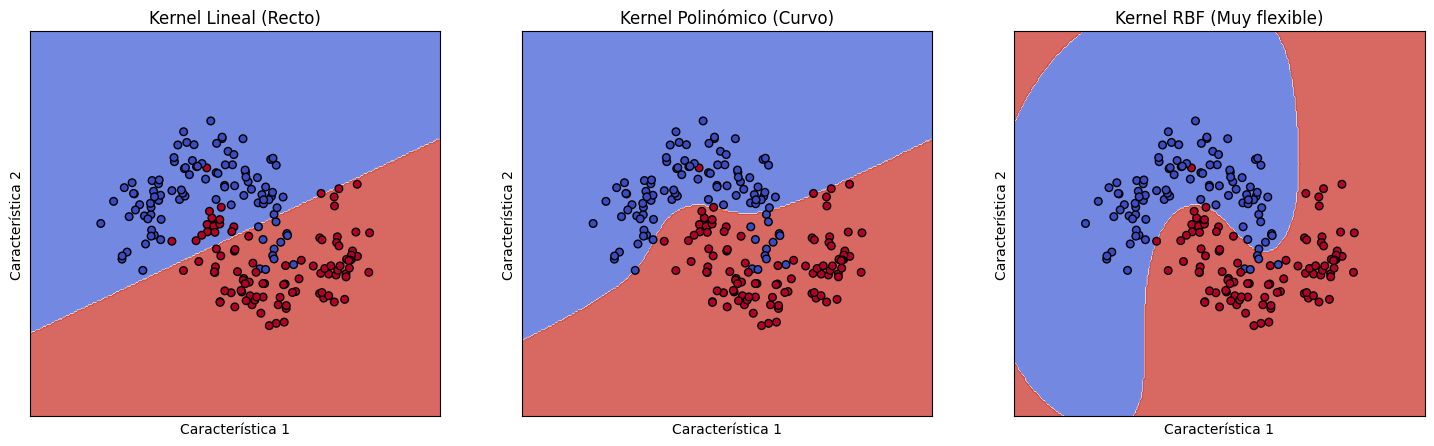

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import svm, datasets

# 1. GENERAR DATOS DE EJEMPLO (Dos lunas entrelazadas)
# Usamos esto porque una línea recta no puede separarlos bien.
X, y = datasets.make_moons(n_samples=200, noise=0.2, random_state=42)

# 2. DEFINIR LOS MODELOS (KERNELS)
# Vamos a probar 3 tipos de "lentes" o formas de separar los datos
modelos = (
    svm.SVC(kernel='linear'),       # Lineal: Una línea recta
    svm.SVC(kernel='poly', degree=3), # Polinómico: Curvas suaves
    svm.SVC(kernel='rbf')           # RBF: Curvas complejas (el más potente usualmente)
)

# Entrenamos los modelos
modelos = [clf.fit(X, y) for clf in modelos]

# 3. CREAR EL GRID (La cuadrícula de fondo)
# Creamos una malla de puntos para pintar el fondo y ver la frontera
def make_meshgrid(x, y, h=.02):
    x_min, x_max = x.min() - 1, x.max() + 1
    y_min, y_max = y.min() - 1, y.max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                         np.arange(y_min, y_max, h))
    return xx, yy

# Función para pintar los contornos
def plot_contours(ax, clf, xx, yy, **params):
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    out = ax.contourf(xx, yy, Z, **params)
    return out

# 4. GRAFICAR TODO
titulos = ('Kernel Lineal (Recto)',
           'Kernel Polinómico (Curvo)',
           'Kernel RBF (Muy flexible)')

fig, sub = plt.subplots(1, 3, figsize=(18, 5))
plt.subplots_adjust(wspace=0.2, hspace=0.2)

X0, X1 = X[:, 0], X[:, 1]
xx, yy = make_meshgrid(X0, X1)

for clf, title, ax in zip(modelos, titulos, sub.flatten()):
    # Pintar el Grid (Fronteras)
    plot_contours(ax, clf, xx, yy, cmap=plt.cm.coolwarm, alpha=0.8)
    # Pintar los puntos reales (Datos)
    ax.scatter(X0, X1, c=y, cmap=plt.cm.coolwarm, s=30, edgecolors='k')

    ax.set_xlim(xx.min(), xx.max())
    ax.set_ylim(yy.min(), yy.max())
    ax.set_xlabel('Característica 1')
    ax.set_ylabel('Característica 2')
    ax.set_xticks(())
    ax.set_yticks(())
    ax.set_title(title)

plt.show()

In [5]:
# Producto B — Curvas ROC comparando ensambles (RandomForest, AdaBoost, GradientBoosting)
# Receiver Operator Characteristic curve
# Características de funcionamiento del receptor

In [6]:
# Función para plotear ROC de varios ensambles
def plot_ensembles_roc(n_estimators=50, max_depth=3, test_size=0.3, random_state=0):
    data = load_breast_cancer()
    X, y = data.data, data.target

    # escalar
    scaler = StandardScaler()
    X = scaler.fit_transform(X)

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, random_state=random_state, stratify=y)

    # modelos
    models = {
        "RandomForest": RandomForestClassifier(n_estimators=int(n_estimators), max_depth=int(max_depth), random_state=0),
        "AdaBoost": AdaBoostClassifier(n_estimators=int(n_estimators), random_state=0),
        "GradientBoosting": GradientBoostingClassifier(n_estimators=int(n_estimators), max_depth=int(max_depth), random_state=0)
    }

    plt.figure(figsize=(8,6))
    for name, model in models.items():
        model.fit(X_train, y_train)
        # obtener probabilidades de la clase positiva
        if hasattr(model, "predict_proba"):
            probs = model.predict_proba(X_test)[:,1]
        else:
            # fallback a decision_function si existe
            try:
                probs = model.decision_function(X_test)
            except:
                # como último recurso, usar predicciones (mal recomendado)
                probs = model.predict(X_test)

        fpr, tpr, _ = roc_curve(y_test, probs)
        score = auc(fpr, tpr)
        plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {score:.3f})")

    # línea aleatoria
    plt.plot([0,1], [0,1], color='navy', lw=1, linestyle='--')
    plt.xlim([-0.02,1.02])
    plt.ylim([-0.02,1.02])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'ROC Curves - Comparación de Ensambles (n_estimators={int(n_estimators)}, max_depth={int(max_depth)})')
    plt.legend(loc="lower right")
    plt.grid(alpha=0.3)
    plt.show()

# widgets para ensembles
n_estimators_w = widgets.IntSlider(value=50, min=10, max=300, step=10, description='n_estimators:')
max_depth_w = widgets.IntSlider(value=3, min=1, max=10, step=1, description='max_depth:')
test_size_w = widgets.FloatSlider(value=0.3, min=0.1, max=0.5, step=0.05, description='test_size:')

out2 = widgets.interactive_output(plot_ensembles_roc, {'n_estimators': n_estimators_w, 'max_depth': max_depth_w, 'test_size': test_size_w})
display(Markdown("### Producto B — Curvas ROC comparando ensambles"))
display(widgets.HBox([n_estimators_w, max_depth_w, test_size_w]), out2)


### Producto B — Curvas ROC comparando ensambles

Output()